In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.metrics import classification_report , confusion_matrix , accuracy_score , auc
from sklearn.model_selection import train_test_split

import cv2
#from google.colab.patches import cv2_imshow
from PIL import Image 
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Input, Dense,Conv2D , MaxPooling2D, Flatten,BatchNormalization,Dropout
from tensorflow.keras.preprocessing import image_dataset_from_directory
import tensorflow_hub as hub 

## Load The Data

In [2]:
from keras.preprocessing.image import ImageDataGenerator

In [3]:
train_data = tf.keras.preprocessing.image_dataset_from_directory(
 "/kaggle/input/100-bird-species/train",
    batch_size=64,
  image_size=(224,224), shuffle=True
)

Found 84635 files belonging to 525 classes.


In [3]:
# test data have less images hence we take valid data as test data
val_data = tf.keras.preprocessing.image_dataset_from_directory(
 "/kaggle/input/100-bird-species/valid",
    batch_size=64,
  image_size=(224,224), shuffle=True
)

Found 2625 files belonging to 525 classes.


In [4]:
test_data = tf.keras.preprocessing.image_dataset_from_directory(
 "/kaggle/input/100-bird-species/test",
    batch_size=64,
  image_size=(224,224), shuffle=True
)

Found 2625 files belonging to 525 classes.


In [4]:
datagen = ImageDataGenerator(rescale=1.0/255.0)

# Use the 'datagen' to preprocess the images loaded by 'image_data_from_directory'
train_scaled_data = datagen.flow_from_directory(
    "/kaggle/input/100-bird-species/train",
    target_size=(224, 224),
    batch_size=256,shuffle=True
)

test_scaled_data = datagen.flow_from_directory(
    "/kaggle/input/100-bird-species/test",
    target_size=(224, 224),
    batch_size=256,shuffle=True
)

valid_scaled_data = datagen.flow_from_directory(
    "/kaggle/input/100-bird-species/valid",
    target_size=(224, 224),
    batch_size=256,shuffle=True
)

Found 84635 images belonging to 525 classes.
Found 2625 images belonging to 525 classes.
Found 2625 images belonging to 525 classes.


In [22]:
# train_scaled_data

1328.125

In [6]:

for img_batch,img_label in train_scaled_data:
    print(img_batch.shape)
    print(img_label.shape)
    break

(256, 224, 224, 3)
(256, 525)


In [19]:
type(img_label)

numpy.ndarray

In [5]:
# print(len(train_data))
# print(len(test_data))
# print(len(val_data))

1323
42
42


In [7]:
class_labels=train_data.class_names
class_labels[:10]

['ABBOTTS BABBLER',
 'ABBOTTS BOOBY',
 'ABYSSINIAN GROUND HORNBILL',
 'AFRICAN CROWNED CRANE',
 'AFRICAN EMERALD CUCKOO',
 'AFRICAN FIREFINCH',
 'AFRICAN OYSTER CATCHER',
 'AFRICAN PIED HORNBILL',
 'AFRICAN PYGMY GOOSE',
 'ALBATROSS']

In [8]:
dict_class_labels = {j:i for i,j in enumerate(class_labels)}
len(dict_class_labels)

525

## Training Images Data Preprocessing

In [5]:
# train_folder_path = "/kaggle/input/100-bird-species/train"
# image_data = []
# image_label = []
# for i in os.listdir(train_folder_path):
#     #print(i)
#     path_class = os.path.join("/kaggle/input/100-bird-species/train",i)
#     #print(path_class)
#     for j in os.listdir(path_class):
#         image = Image.open(path_class+"/"+j)
#         image = image.resize((224,224))
#         image = image.convert("RGB")
#         image = np.array(image)
#         image_data.append(image)
#         image_label.append(dict_class_labels[i])

In [6]:
# print(len(image_data))
# print(len(image_label))

84635
84635


## Testing Images Data Preprocessing

In [7]:
# test_folder_path = "/kaggle/input/100-bird-species/test"
# image_data1 = []
# image_label1 = []
# for i in os.listdir(test_folder_path):
#     #print(i)
#     path_class = os.path.join("/kaggle/input/100-bird-species/test",i)
#     #print(path_class)
#     for j in os.listdir(path_class):
#         image = Image.open(path_class+"/"+j)
#         image = image.resize((224,224))
#         image = image.convert("RGB")
#         image = np.array(image)
#         image_data1.append(image)
#         image_label1.append(dict_class_labels[i])

In [8]:
# print(len(image_data1))
# print(len(image_label1))

2625
2625


## Validation Images Data Preprocessing

In [9]:
# valid_folder_path = "/kaggle/input/100-bird-species/valid"
# image_data2 = []
# image_label2 = []
# for i in os.listdir(valid_folder_path):
#     #print(i)
#     path_class = os.path.join("/kaggle/input/100-bird-species/valid",i)
#     #print(path_class)
#     for j in os.listdir(path_class):
#         image = Image.open(path_class+"/"+j)
#         if i=="PARAKETT AUKLET":
#             i=i.replace("PARAKETT AUKLET","PARAKETT  AUKLET")
#             print(i)
#         image = image.resize((224,224))
#         image = image.convert("RGB")
#         image = np.array(image)
#         image_data2.append(image)
#         image_label2.append(dict_class_labels[i])

PARAKETT  AUKLET


In [14]:
# print(len(image_data2))
# print(len(image_label2))

2625
2625


In [9]:
len(class_labels)

525

In [10]:
class_labels[:5]

['ABBOTTS BABBLER',
 'ABBOTTS BOOBY',
 'ABYSSINIAN GROUND HORNBILL',
 'AFRICAN CROWNED CRANE',
 'AFRICAN EMERALD CUCKOO']

In [18]:
# x_train = np.array(image_data)
# y_train = np.array(image_label)

# x_test = np.array(image_data1)
# y_test = np.array(image_label1)

# x_valid = np.array(image_data2)
# y_valid = np.array(image_label2)

In [19]:
# print(x_train.shape)
# print(y_train.shape)
# print(x_test.shape)
# print(y_test.shape)
# print(x_valid.shape)
# print(y_valid.shape)

(84635, 224, 224, 3)
(84635,)
(2625, 224, 224, 3)
(2625,)
(2625, 224, 224, 3)
(2625,)


In [21]:
# import joblib

# joblib.dump(x_train,"x_train.joblib")
# joblib.dump(y_train,"y_train.joblib")

# joblib.dump(x_test,"x_test.joblib")
# joblib.dump(y_test,"y_test.joblib")

# joblib.dump(x_valid,"x_valid.joblib")
# joblib.dump(y_valid,"y_valid.joblib")

['y_valid.joblib']

In [5]:
# import joblib
# x_train_data=joblib.load("/kaggle/working/x_train.joblib")
# y_train_data=joblib.load("/kaggle/working/y_train.joblib")

# x_test_data=joblib.load("/kaggle/working/x_test.joblib")
# y_test_data=joblib.load("/kaggle/working/y_test.joblib")

# # x_valid_data=joblib.load("/kaggle/working/x_valid.joblib")
# # y_valid_data=joblib.load("/kaggle/working/y_valid.joblib")

In [ ]:
# x_train_data_scaled = x_train_data/255
# x_test_data_scaled = x_test_data/255

# Train Image data

# Resizing and Scaling

In [10]:
# resizing_and_rescaling = tf.keras.Sequential([
#     tf.keras.layers.experimental.preprocessing.Resizing(224,224),
#     tf.keras.layers.experimental.preprocessing.Rescaling(1.0/255)
# ])

# Data Augmentation

In [11]:
# data_augmentation = tf.keras.Sequential([
#     tf.keras.layers.experimental.preprocessing.RandomContrast(0.3),
#     tf.keras.layers.experimental.preprocessing.RandomFlip('horizontal_and_vertical'),
#     tf.keras.layers.experimental.preprocessing.RandomZoom(0.3),
#     tf.keras.layers.experimental.preprocessing.RandomRotation(0.2)
# ])

# CNN Model

In [23]:
# IMAGE_SIZE=224
# CHANNELS=3
# BATCH_SIZE=64
# EPOCHS=10

# input_shape=(BATCH_SIZE , IMAGE_SIZE, IMAGE_SIZE, CHANNELS)

# model= tf.keras.models.Sequential([
#   resizing_and_rescaling,
#   data_augmentation,
#   # Convolution layer 1
#   tf.keras.layers.Conv2D(filters=120, kernel_size=(3,3), strides=(1,1),padding='same',activation='relu',input_shape=input_shape),
#   tf.keras.layers.MaxPool2D(pool_size=(2,2)),
#   # Convolution layer 2
#   tf.keras.layers.Conv2D(filters=100, kernel_size=(3,3),strides=(1,1),padding='same',activation='relu'),
#   tf.keras.layers.MaxPool2D(pool_size=(2,2)),
#   # Convolution layer 3
#   tf.keras.layers.Conv2D(filters=80, kernel_size=(3,3),strides=(1,1),padding='same',activation='relu'),
#   tf.keras.layers.MaxPool2D(pool_size=(2,2)),
#   # Convolution layer 4
#   tf.keras.layers.Conv2D(filters=60, kernel_size=(3,3),strides=(1,1),padding='same',activation='relu'),
#   tf.keras.layers.MaxPool2D(pool_size=(2,2)),

#   # Flatten Layers
#   tf.keras.layers.Flatten(),

#   # Dense layers
#   tf.keras.layers.Dense(units=1000,activation='relu'),
#   tf.keras.layers.Dropout(0.4),
#   tf.keras.layers.Dense(units=1000,activation='relu'),
#   tf.keras.layers.Dropout(0.3),
#   tf.keras.layers.Dense(units=1000,activation='relu'),
#   tf.keras.layers.Dropout(0.2),
#   tf.keras.layers.Dense(units=len(class_labels) ,activation='softmax')

# ])

# model.build(input_shape=input_shape)

In [24]:
# model.summary()

In [22]:
# model.compile(optimizer="adam",
#              loss="sparse_categorical_crossentropy",
#              metrics=["accuracy"])

# history = model.fit(train_data ,  batch_size=64 ,epochs=20,
#                 verbose=1,
#                 validation_data=val_data) # epochs=5

In [11]:
path = "/kaggle/input/mobilenet-v2/tensorflow2/100-224-classification/2"

model_hub = hub.KerasLayer(path, input_shape=(224,224,3), trainable=False)


num_class = 525
model = Sequential()
model.add(model_hub)
model.add(Dense(1000,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(1000,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(units=num_class, activation="softmax"))


model.compile(optimizer="adam",loss="categorical_crossentropy",
             metrics=["accuracy"])


model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1001)              3540265   
                                                                 
 dense (Dense)               (None, 1000)              1002000   
                                                                 
 dropout (Dropout)           (None, 1000)              0         
                                                                 
 dense_1 (Dense)             (None, 1000)              1001000   
                                                                 
 dropout_1 (Dropout)         (None, 1000)              0         
                                                                 
 dense_2 (Dense)             (None, 525)               525525    
                                                                 
Total params: 6,068,790
Trainable params: 2,528,525
Non-

In [13]:
history = model.fit(train_scaled_data ,batch_size=256,epochs=10,
                verbose=1,
                validation_data=valid_scaled_data) # epochs=5

Epoch 1/10
331/331 [==============================] - 282s 851ms/step - loss: 0.7050 - accuracy: 0.8073 - val_loss: 0.4785 - val_accuracy: 0.8651
Epoch 2/10
331/331 [==============================] - 243s 735ms/step - loss: 0.4994 - accuracy: 0.8580 - val_loss: 0.4484 - val_accuracy: 0.8750
Epoch 3/10
331/331 [==============================] - 256s 773ms/step - loss: 0.3835 - accuracy: 0.8865 - val_loss: 0.4562 - val_accuracy: 0.8716
Epoch 4/10
331/331 [==============================] - 244s 738ms/step - loss: 0.3082 - accuracy: 0.9073 - val_loss: 0.4301 - val_accuracy: 0.8781
Epoch 5/10
331/331 [==============================] - 245s 739ms/step - loss: 0.2510 - accuracy: 0.9219 - val_loss: 0.4412 - val_accuracy: 0.8872
Epoch 6/10
331/331 [==============================] - 243s 734ms/step - loss: 0.2247 - accuracy: 0.9288 - val_loss: 0.4372 - val_accuracy: 0.8888
Epoch 7/10
331/331 [==============================] - 254s 767ms/step - loss: 0.2005 - accuracy: 0.9359 - val_loss: 0.4687 -

# Accuracy and Loss

In [15]:
loss,acc = model.evaluate(train_scaled_data)
print("Loss on Train data:",loss)
print("Accuracy on Train data:",acc)

loss1,acc1 = model.evaluate(train_scaled_data)

print("Loss on Test data:",loss1)
print("Accuracy on Test data:",acc1)

331/331 [==============================] - 310s 936ms/step - loss: 0.0416 - accuracy: 0.9874
Loss on Train data: 0.04162685573101044
Accuracy on Train data: 0.987381100654602
331/331 [==============================] - 238s 717ms/step - loss: 0.0416 - accuracy: 0.9874
Loss on Test data: 0.04162687063217163
Accuracy on Test data: 0.987381100654602


In [16]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

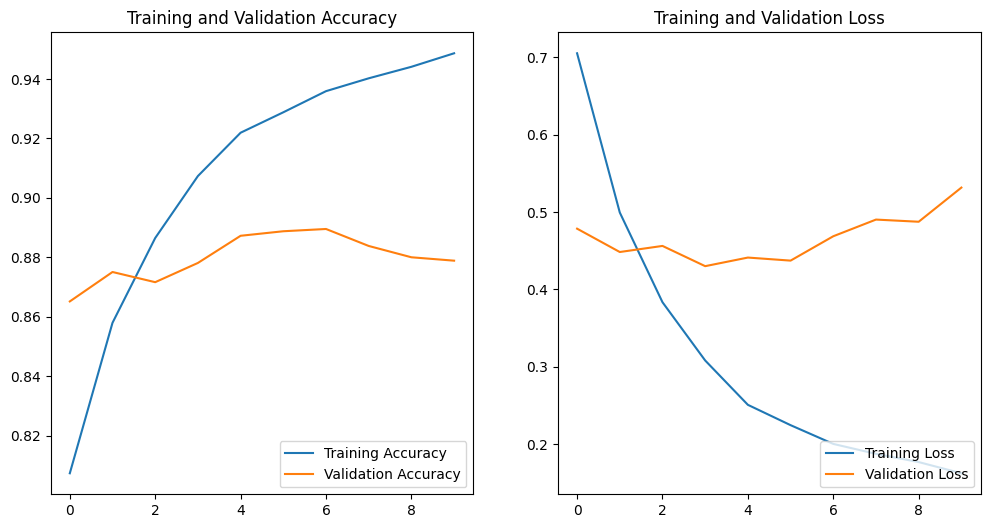

In [18]:
EPOCHS=10
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.plot(range(EPOCHS),acc, label="Training Accuracy")
plt.plot(range(EPOCHS),val_acc, label="Validation Accuracy")
plt.legend(loc="lower right")
plt.title("Training and Validation Accuracy")

#plt.figure(figsize=(6,6))
plt.subplot(1,2,2)
plt.plot(range(EPOCHS),loss, label="Training Loss")
plt.plot(range(EPOCHS),val_loss, label="Validation Loss")
plt.legend(loc="lower right")
plt.title("Training and Validation Loss")
plt.show()